In [ ]:
This notebook uses synthetic data generated in Python, to demonstrate the analysis workflow

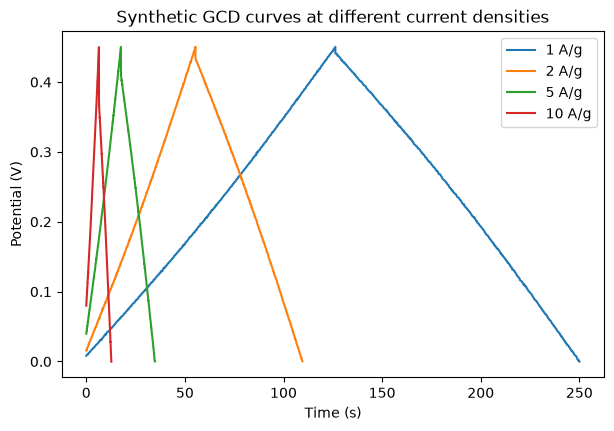

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Settings for our fake electrode
mass = 0.002                               # active mass in grams (2 mg)
current_densities = [1, 2, 5, 10]          # A/g
Cs_true = {1: 280, 2: 250, 5: 210, 10: 170}  # true specific capacitance, F/g
V_min, V_max = 0.0, 0.45                   # potential window in volts
R = 4.0                                    # series resistance in ohms (causes the iR drop)

rng = np.random.default_rng(1)             # makes the noise repeatable

def make_gcd(J, Cs, n=400):
    """Make one fake charge-discharge cycle: returns time (s) and potential (V)."""
    I = J * mass                           # current in amperes
    drop = I * R                           # iR drop in volts

    # Charging: potential rises linearly (with a small bend)
    t_ch = Cs * (V_max - drop - V_min) / J / 0.98     # 98% coulombic efficiency
    frac = np.linspace(0, 1, n)
    V_ch = (V_min + drop) + (V_max - V_min - drop) * frac - 0.015 * np.sin(np.pi * frac)
    t_c = frac * t_ch

    # Discharging: starts after the iR drop and falls to V_min
    dV = V_max - drop - V_min
    t_dis = Cs * dV / J
    V_dis = (V_max - drop) - dV * frac + 0.015 * np.sin(np.pi * frac)
    t_d = t_ch + frac * t_dis

    t = np.concatenate([t_c, t_d])
    V = np.concatenate([V_ch, V_dis])
    V += rng.normal(0, 0.0005, size=V.size)           # small noise
    return t, V

gcd_data = {}
plt.figure(figsize=(7, 4.5))
for J in current_densities:
    t, V = make_gcd(J, Cs_true[J])
    gcd_data[J] = (t, V)
    plt.plot(t, V, label=f"{J} A/g")

plt.xlabel("Time (s)")
plt.ylabel("Potential (V)")
plt.title("Synthetic GCD curves at different current densities")
plt.legend()
plt.show()

In [ ]:
Calculating the specific capacitance, energy density, power density

J (A/g)   C (F/g)   E (Wh/kg)   P (W/kg)
    1      280.4         7.6         221
    2      250.3         6.5         433
    5      210.0         4.9        1025
   10      169.8         3.2        1853


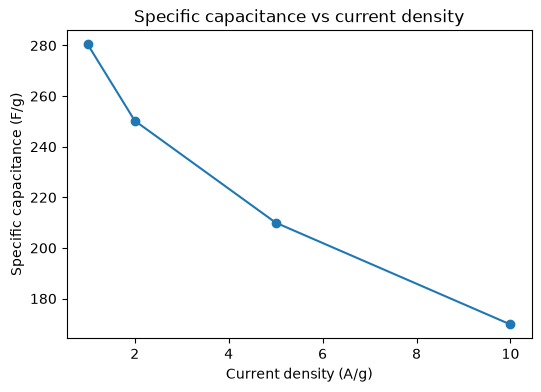

In [2]:
results = []
print("J (A/g)   C (F/g)   E (Wh/kg)   P (W/kg)")

for J in current_densities:
    t, V = gcd_data[J]

    k = np.argmin(np.diff(V))        # biggest sudden drop = the iR drop
    t_dis = t[-1] - t[k + 1]         # discharge time in seconds (after the drop)
    dV = V[k + 1] - V[-1]            # potential window used, without the iR drop

    C = J * t_dis / dV               # specific capacitance in F/g
    E = C * dV**2 / 7.2              # energy density in Wh/kg
    P = E * 3600 / t_dis             # power density in W/kg

    results.append((J, C, E, P))
    print(f"{J:>5}   {C:8.1f}   {E:9.1f}   {P:9.0f}")

J_list = [r[0] for r in results]
C_list = [r[1] for r in results]

plt.figure(figsize=(6, 4))
plt.plot(J_list, C_list, "o-")
plt.xlabel("Current density (A/g)")
plt.ylabel("Specific capacitance (F/g)")
plt.title("Specific capacitance vs current density")
plt.show()